In [1]:
import pandas as pd
from pathlib import Path

In [70]:
f = "../data/processed/inout/labels.parquet"

In [48]:
df = pd.read_parquet("../data/processed/inout/labels.parquet")

In [108]:
df.label.value_counts()

label
0    2714
1     231
Name: count, dtype: int64

In [109]:
df.label.value_counts(normalize=True)

label
0    0.921562
1    0.078438
Name: proportion, dtype: float64

In [110]:
df.decision.value_counts()

decision
unanimous      2476
adjudicated     469
Name: count, dtype: int64

In [111]:
df[df.label==1]["decision"].value_counts()

decision
unanimous      117
adjudicated    114
Name: count, dtype: int64

In [57]:
easy_decisions = df[(df.label==1)&(df.decision=="unanimous")]

# SetFit

In [ ]:
from setfit import sample_dataset
from setfit import SetFitModel, SetFitTrainer
from datasets import load_dataset
from gami2_map.data.load import load_huggingface_splits
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay


In [ ]:
ds = load_huggingface_splits("inout")          # test, train, validation
# Combine text columns

def join_title_text(row):
    return {"text": " ".join(part for part in (row["title"], row["text"]) if part)}

ds = ds.map(join_title_text)          # works on a DatasetDict (all splits) or a single Dataset

# : The exact number of examples to draw for each class (e.g., 8 or 16 for few-shot learning)
few_shot_train = sample_dataset(ds["train"], label_column="label", num_samples=16, seed=42)



Map: 100%|██████████| 471/471 [00:00<00:00, 17764.16 examples/s]


In [91]:
# Step 2: Load a pretrained Sentence Transformer model
model = SetFitModel.from_pretrained(
    "sentence-transformers/all-mpnet-base-v2"
)

# Step 3: Create a SetFit trainer
trainer = SetFitTrainer(
    model=model,
    train_dataset=few_shot_train,
    eval_dataset=ds["validation"],
    metric="accuracy",
    column_mapping={
        "text": "text",
        "label": "label"
    }
)
# Step 4: Fine-tune the model
trainer.train()

# Step 5: Evaluate the model
metrics = trainer.evaluate()
print(metrics)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7902.54it/s]
model_head.pkl not found on HuggingFace Hub, initialising classification head with random weights. You should TRAIN this model on a downstream task to use it for predictions and inference.
/var/folders/zz/l58996v55z3bgswzbcr81wt80000gn/T/ipykernel_62102/3638317996.py:7: DeprecationWarning: `SetFitTrainer` has been deprecated and will be removed in v2.0.0 of SetFit. Please use `Trainer` instead.
  trainer = SetFitTrainer(
Applying column mapping to the training dataset
Applying column mapping to the evaluation dataset
Map: 100%|██████████| 32/32 [00:00<00:00, 5474.70 examples/s]
***** Running training *****
  Num unique pairs = 1280
  Batch size = 16
  Num epochs = 1
/Users/ishitagopal/Documents/Projects/gami2-map/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(lo

Step,Training Loss
1,-0.003774
50,0.005584


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.15it/s]
***** Running evaluation *****

{'accuracy': 0.8110403397027601}


In [93]:
model.save_pretrained("../results/inout/setfit-mpnet-fewshot")


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.65it/s]


In [ ]:
texts = ds["validation"]["text"]
y_true = np.asarray(ds["validation"]["label"])
proba = model.predict_proba(texts, as_numpy=True)[:, 1]     # P(include)
y_pred = (proba >= 0.5).astype(int)                          # same threshold as the pipeline



In [106]:
y_pred = (proba >= 0.5).astype(int)                          # same threshold as the pipeline


              precision    recall  f1-score   support

     exclude      0.981     0.811     0.888       434
     include      0.268     0.811     0.403        37

    accuracy                          0.811       471
   macro avg      0.624     0.811     0.645       471
weighted avg      0.925     0.811     0.850       471

[[352  82]
 [  7  30]]


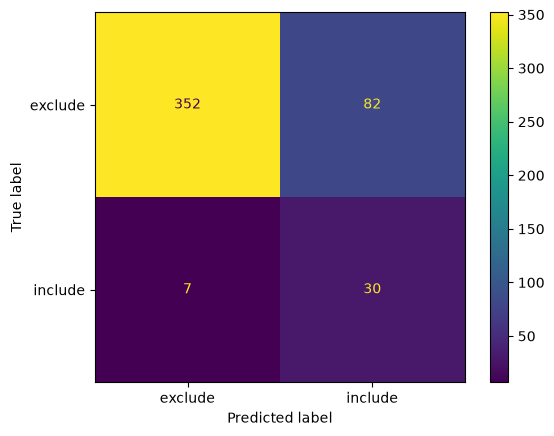

In [107]:
import matplotlib
print(classification_report(y_true, y_pred, target_names=["exclude", "include"], digits=3))
print(confusion_matrix(y_true, y_pred))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=["exclude", "include"])
